# Preparación de los datos
Procedemos a realizar las importaciones necesarias, cargar los datos y eliminar los valores nulos. Además, comprobaremos que el nombre de las columnas no contengan espacios en blanco y que los datos sean consistentes. 

In [ ]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

df = pd.read_csv('/workspace/dataset.csv')

df.columns = df.columns.str.strip()

key_columns = ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'yr_built', 'price']
df_cleaned = df.dropna(subset=key_columns)

print("Valores nulos restantes en columnas clave:")
print(df_cleaned[key_columns].isnull().sum())

Valores nulos restantes en columnas clave:
bedrooms       0
bathrooms      0
sqft_living    0
sqft_lot       0
floors         0
yr_built       0
price          0
dtype: int64


# División del dataset
Dividimos el conjunto en tres subconjuntos: de entrenamiento, validación y de pruebas. 


In [6]:
features = ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'yr_built']
X = df_cleaned[features]
y = df_cleaned['price']

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=(0.20/0.85), random_state=42)

print(f"Tamaño del set de entrenamiento: {len(X_train)} (65%)")
print(f"Tamaño del set de validación: {len(X_val)} (20%)")
print(f"Tamaño del set de prueba: {len(X_test)} (15%)")

Tamaño del set de entrenamiento: 14048 (65%)
Tamaño del set de validación: 4323 (20%)
Tamaño del set de prueba: 3242 (15%)


# Normalización de las características
Procedemos a normalizar las características numéricas excepto la variable objetivo. 

In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Conversión de datos a tensores de PyTorch

In [8]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

# Creación de DataLoaders


In [9]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=4)

# Definición del modelo
Creamos una red neuronal feed-forward con dos capas ocultas y una capa de salida de una sola neurona. 

In [11]:
class HousePriceNN(nn.Module):
    def __init__(self, input_dim):
        super(HousePriceNN, self).__init__()
        self.hidden1 = nn.Linear(input_dim, 64)
        self.hidden2 = nn.Linear(64, 32)
        self.output = nn.Linear(32, 1)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        x = self.relu(self.hidden1(x))
        x = self.relu(self.hidden2(x))
        x = self.output(x)
        return x

input_dim = X_train_tensor.shape[1]
model = HousePriceNN(input_dim)

# Definir la función de pérdida y el optimizador
Usaremos la MSE como función de pérdida y Adam como optimizador. 

In [12]:
criterion = nn.MSELoss()

optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=0.01)

# Entrenamiento del modelo
Entrenaremos el modelo durante 100 épocas y validaremos el modelo en cada época. 

In [13]:
epochs = 100
train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0
    
    for inputs, targets in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item() * inputs.size(0)
        
    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)
    
    model.eval()
    running_val_loss = 0.0
    
    with torch.no_grad():
        for inputs, targets in val_loader:
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            running_val_loss += loss.item() * inputs.size(0)
            
    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)
    
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

Epoch 1/100 | Train Loss: 420317070133.0660 | Val Loss: 422023555675.0775
Epoch 10/100 | Train Loss: 115733750763.0068 | Val Loss: 109961900826.9442
Epoch 20/100 | Train Loss: 75281310829.6310 | Val Loss: 72220316696.3979
Epoch 30/100 | Train Loss: 63449673611.3713 | Val Loss: 61266374163.3051
Epoch 40/100 | Train Loss: 58761921951.1982 | Val Loss: 57272685401.0049
Epoch 50/100 | Train Loss: 56988237996.6105 | Val Loss: 55811709198.5084
Epoch 60/100 | Train Loss: 56189001032.8929 | Val Loss: 55137857779.5050
Epoch 70/100 | Train Loss: 55635711314.2232 | Val Loss: 54725135580.0546
Epoch 80/100 | Train Loss: 55195807825.6401 | Val Loss: 54373222705.0918
Epoch 90/100 | Train Loss: 54808332094.3964 | Val Loss: 54032964716.2508
Epoch 100/100 | Train Loss: 54450931840.2916 | Val Loss: 53732281449.8820


# Graficar la curva de pérdida
Tras entrenar el modelo es necesario graficar las pérdidas para ver como aprende el modelo y si hay sobreajuste o subajuste.  

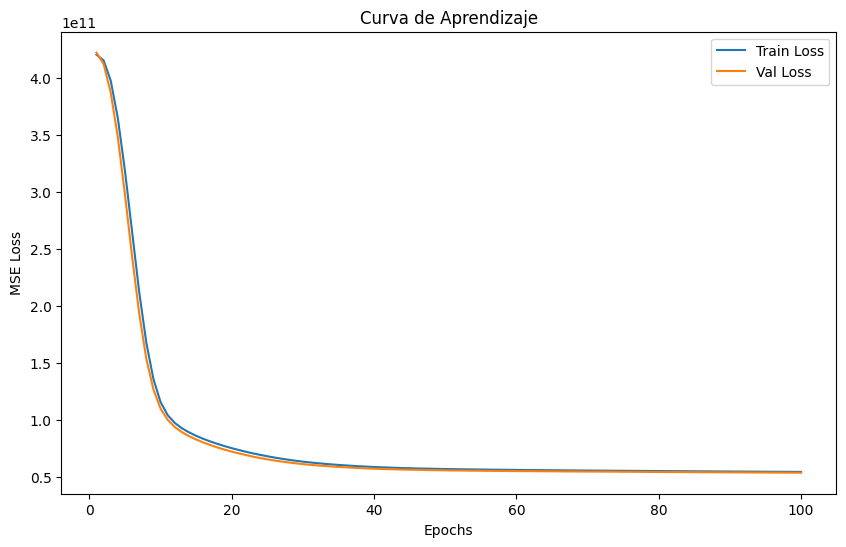

In [14]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), train_losses, label='Train Loss')
plt.plot(range(1, epochs + 1), val_losses, label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Curva de Aprendizaje')
plt.legend()
plt.show()

# Evaluar el modelo

In [15]:
model.eval()
test_loss = 0.0

with torch.no_grad():
    for inputs, targets in test_loader:
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        test_loss += loss.item() * inputs.size(0)

final_test_loss = test_loss / len(test_loader.dataset)

print("--- Evaluación Final en el Conjunto de Prueba ---")
print(f"Pérdida final en el conjunto de prueba (MSE): {final_test_loss:.4f}")

--- Evaluación Final en el Conjunto de Prueba ---
Pérdida final en el conjunto de prueba (MSE): 64967951297.4608
